In [1]:
import os
import sys
#sys.path.insert(0, "../../Python/cellular_cycle") # add path to the model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
from numpy.linalg import norm
import datetime
import math
import multiprocess as mp
import time
import pickle

## Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count

# to match Austin's ouput and use his functions, simulation with ODE should use omega=1 and stochastic with omega=200 (the default)
from cell_cycle_death_model import model
#from model_fxns import * # functions to evaluate simulation output; includes plotObs()

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


# Directory containing cell fate data
DATADIR = Path('../../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [2]:
t = np.linspace(0, 1000, 1000001)
# t = np.linspace(0, 20000, 200001)
# t = np.linspace(0, 50000, 500001)

model.parameters['AKT'].value = 1
model.parameters['ERK'].value = 1
model.parameters['FAK'].value = 1

In [3]:
# Importing the parameters:
new_param = pd.read_csv('parameters.csv')

for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

Stress
b
Hippo_tot
Yap_tot
AKT_tot
ERK_tot
FAK_tot
skp2_tot
p21_tot
cdh1_tot
CycD_tot
K_1E2F
V_1E2F
k_cd4
k_myc1
k_CE
d_CE
K_i13
K_i14
V_sac
V_da
V_sec
V_de
V_sf
V_fs
V_dfa
v_scdh1a
v_2fak
v_s2p21
K_AFAK
K_dfa
K_fs
K_cf
K_cac
K_cec
K_da
K_de
K_sp21
k_dcdh1a
F_n.1
K_p21fak.1
k_CDF
K_DF
K_dcescp2


In [4]:
initial_concentrations = pd.read_csv(os.getcwd() + '/../model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

BAXm_0
BCL2_0


In [5]:
integrator_options = {
    "rtol": 1e-12,
    "atol": 1e-12
}

In [13]:
model.parameters['AKT'].value = 0.3
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 0.4
t = np.linspace(0, 10000, 100000)

In [14]:
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python', integrator_options=integrator_options).run() #deterministic simulation

In [11]:
observables=['obsCycE','obsCdc20', 'obsCycA']; #plot Cyclin E, Cdc20 and Cyclin A

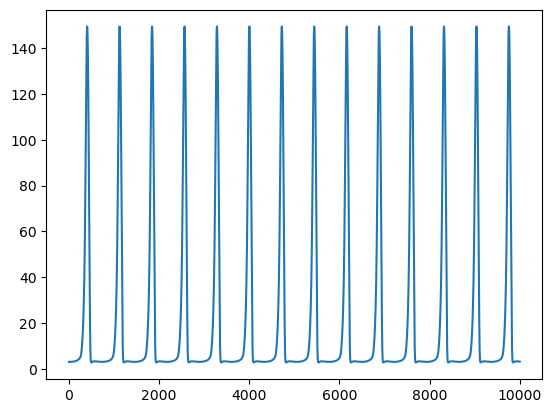

In [16]:

#plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,100000), legend=True)
plt.plot(sim_ode.all['obsCdc20'][90000:])

In [550]:
from scipy.signal import find_peaks

In [551]:
FAKs = list(np.linspace(0.4,0.6,50))
tmp = list(np.linspace(0.6,1,50))
FAKs.extend(tmp)

In [552]:
AKTs = list(np.linspace(0.3,0.6,50))
tmp = [0.6]*50
AKTs.extend(tmp)
ERKs = [0.2]*100

In [553]:
AKTt=[0.3,0.6]
ERKt=[0.2,0.2]
FAKt=[0.4,0.6]

In [554]:
integrator_options = {
    "rtol": 1e-12,
    "atol": 1e-12
}

In [555]:
POINTS=1

In [556]:
def run_lyaps(AKT, ERK, FAK, np=np, model=model, points=POINTS, ScipyOdeSimulator=ScipyOdeSimulator, find_peaks=find_peaks,
             integrator_options=integrator_options, norm=norm, math=math):
    model.parameters['AKT'].value = AKT
    model.parameters['ERK'].value = ERK
    model.parameters['FAK'].value = FAK
    ep = 0.001*200
    t = np.linspace(0, 1000, 1000001)
    t_0 = np.linspace(0, 2000, 2000001)
    all_logz = dict.fromkeys(list(range(1,points+1)))
    
    for kk in range(points):
        sim_ode = ScipyOdeSimulator(model, t_0, verbose=False, compiler='python', integrator_options=integrator_options).run()
        y_out = sim_ode.observables
        
        peaks_cdc, _ = find_peaks(y_out['obsCdc20'], prominence = 0.6, distance = 10)
        new_y = y_out[peaks_cdc[-11]:peaks_cdc[-2]]
        peaks_half = peaks_cdc[peaks_cdc < len(y_out)/2]

        variable_range=y_out[peaks_half[-2]:peaks_half[-1]]
        tmp_loc = (round(len(variable_range)/(points))*(kk))
        
        Initial_1 = variable_range[tmp_loc]
        Initial_1 = [val+ep for val in Initial_1]
        
        prots = ['Skp2_0', 'p21_0', 'p21p_0', 'cdh1act_0', 'cdh1inact_0', 'Myc_0', 'CycD_0', 'CycDp21_0', 'pRb_0',
                 'pRbp_0', 'E2F_0', 'pRbE2F_0', 'CycE_0', 'CycEp21_0', 'CycA_0', 'CycAp21_0', 'CycB_0', 'CycBp21_0',
                 'Cdc20_0']
        prot_init = {prots[i]: Initial_1[i] for i in range(len(prots))}
        
        for key in prot_init.keys():
            model.parameters[key].value = prot_init[key] / model.parameters['omega'].value   
            
        sim_ode1 = ScipyOdeSimulator(model, t, verbose=False, compiler='python', integrator_options=integrator_options).run()
        y_out1 = sim_ode1.observables        
        
        z=[0]*(round((len(y_out1)/2000))+1)
        n=0
        for i in range(0, len(y_out1), 2000):
            window = y_out[peaks_half[-2]+i+tmp_loc-5000:peaks_half[-1]+i+tmp_loc+5000]
            dists = [0]*len(window)
            for j in range(0, len(window)):
                dif = np.asarray(window[j].tolist())-np.asarray(y_out1[i].tolist())
                dists[j] = norm(dif[0:19]/200)
#         for i in range(0, len(y_out1), 2000):
#             dists = [0]*len(variable_range)
#             for j in range(0, len(variable_range)):
#                 dif = [variable_range[j][num]/200-y_out1[i][num]/200 for num in range(19)]
#                 dists[j] = norm(dif)

            z[n] = min(dists)
            n=n+1
        
        logz = [math.log(num) for num in z]
        all_logz[kk+1] = logz
        
    return all_logz
                
        

In [557]:
start = time.time()
all_logz = run_lyaps(AKTs[0], ERKs[0], FAKs[0])
end = time.time()
print(end - start)

319.2383449077606


In [ ]:
start = time.time()
with mp.Pool(processes = 12) as p:
    results = p.starmap(run_lyaps, [(AKTs[0], ERKs[0], FAKs[0]),
                                    (AKTs[49], ERKs[49], FAKs[49]),
                                    (AKTs[99], ERKs[99], FAKs[99])])
end = time.time()
print(end - start)

In [ ]:
results[0]

In [ ]:
tmp=np.argmax(results[1][1])
np.argmin(results[1][1][tmp:])
test = min(results[1][1][tmp:])
math.ceil(test*10)/10

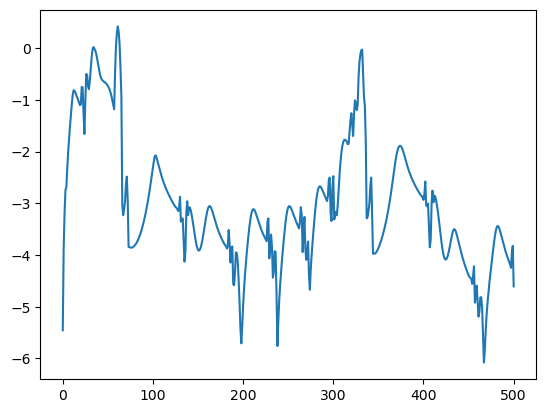

In [558]:
plt.plot(all_logz[1])

In [ ]:
start = time.time()
with mp.Pool(processes = 12) as p:
    results = p.starmap(run_lyaps, [(AKT, ERK, FAK) for AKT in AKTt for ERK in ERKt for FAK in FAKt])
end = time.time()
print(end - start)

In [ ]:
len(all_logz)

In [ ]:
def func(a, b):
    return a + b

In [ ]:
a_args = [1,2,3]
second_arg = 1
with mp.Pool() as pool:
    L = pool.starmap(func, [(1, 1), (2, 1), (3, 1)])

In [ ]:
L

In [559]:
t = np.linspace(0, 1000, 1000001)
t_0 = np.linspace(0, 2000, 2000001)
# t = np.linspace(0, 20000, 200001)
# t = np.linspace(0, 50000, 500001)

In [560]:
model.parameters['AKT'].value = AKTs[0]
model.parameters['ERK'].value = ERKs[0]
model.parameters['FAK'].value = FAKs[0]

In [561]:
sim_ode = ScipyOdeSimulator(model, t_0, verbose=False, compiler='python', integrator_options=integrator_options).run()
y_out = sim_ode.observables

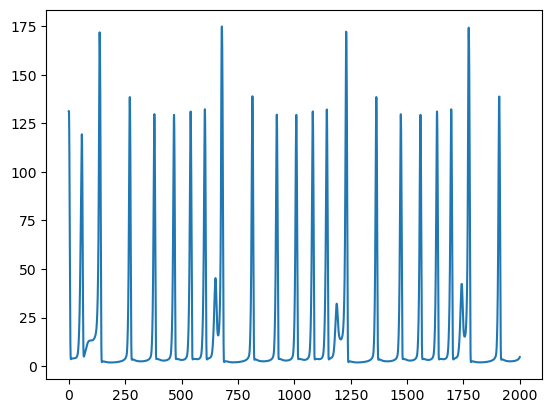

In [562]:
plt.plot(t_0[:],y_out['obsCdc20'][:])

In [503]:
ep = 0.001*200


2000001

In [511]:
peaks_cdc, _ = find_peaks(y_out['obsCdc20'], prominence = 0.6, distance = 10)
new_y = y_out[peaks_cdc[-11]:peaks_cdc[-2]]
peaks_half = peaks_cdc[peaks_cdc < len(y_out)/2]

In [512]:
peaks_half

array([ 64792, 128483, 196742, 269139, 342702, 415622, 487727, 559470,
       631232, 703130, 775120, 847128, 919117, 991088], dtype=int64)

In [513]:
variable_range=y_out[peaks_half[-2]:peaks_half[-1]]


In [514]:
len(variable_range)

71971

In [515]:
points = 20
kk=0
tmp_loc = (round(len(variable_range)/(points))*(kk))
tmp_loc

0

In [516]:
Initial_1 = variable_range[tmp_loc]
Initial_1

(10.89025986, 119.86343205, 420.57177755, 8.95022098, 191.44977902, 91.51515152, 22.00851166, 23.58051418, 166.22877894, 3.62776503, 1.40876552, 106.61758579, 1.46173894, 2.95328504, 6.29812737, 30.35289659, 82.04330768, 10.44699751, 149.39864452, 182.92727799, 16.02852509, 0.19177328, 109.08822672, 0.04461451, 182.02865905, 0., 0., 0., 0., 0., 0.)

In [517]:
Initial_1 = [val+ep for val in Initial_1]
window = y_out[peaks_half[-2]+tmp_loc-5000:peaks_half[-2]+tmp_loc+5000]

In [518]:
len(window)

10000

In [357]:
# prots = ['Skp2_0', 'p21_0', 'p21p_0', 'cdh1act_0', 'cdh1inact_0', 'Myc_0', 'CycD_0', 'CycDp21_0', 'pRb_0',
#  'pRbp_0', 'E2F_0', 'pRbE2F_0', 'CycE_0', 'CycEp21_0', 'CycA_0', 'CycAp21_0', 'CycB_0', 'CycBp21_0',
#  'Cdc20_0', 'BAX_0', 'BAXmBCL2_0', 'BH3_0', 'BH3BCL2_0', 'BAXm_0', 'BCL2_0']
# prot_init = {prots[i]: Initial_1[i] for i in range(len(prots))}
# #del prot_init['BAXm_0']
# #del prot_init['BCL2_0']

In [519]:
prots = ['Skp2_0', 'p21_0', 'p21p_0', 'cdh1act_0', 'cdh1inact_0', 'Myc_0', 'CycD_0', 'CycDp21_0', 'pRb_0',
 'pRbp_0', 'E2F_0', 'pRbE2F_0', 'CycE_0', 'CycEp21_0', 'CycA_0', 'CycAp21_0', 'CycB_0', 'CycBp21_0',
 'Cdc20_0']
prot_init = {prots[i]: Initial_1[i] for i in range(len(prots))}
#del prot_init['BAXm_0']
#del prot_init['BCL2_0']

In [520]:
model.parameters['Cdc20_0'].value

0.7478974970085743

In [521]:
for key in prot_init.keys():
    model.parameters[key].value = prot_init[key] / model.parameters['omega'].value

In [522]:
model.parameters['Cdc20_0'].value

0.7479932225853936

In [524]:
t = np.linspace(0, 1000, 1000001)
#t = np.linspace(0, 10, 10001)

In [525]:
sim_ode1 = ScipyOdeSimulator(model, t, verbose=False, compiler='python', integrator_options=integrator_options).run()
y_out1 = sim_ode1.observables


In [526]:
(window['obsCdc20'][4999]/200)
#0.746989397271882

0.7470019128442452

In [527]:
y_out1['obsCdc20'][0]/200

0.7479932225853936

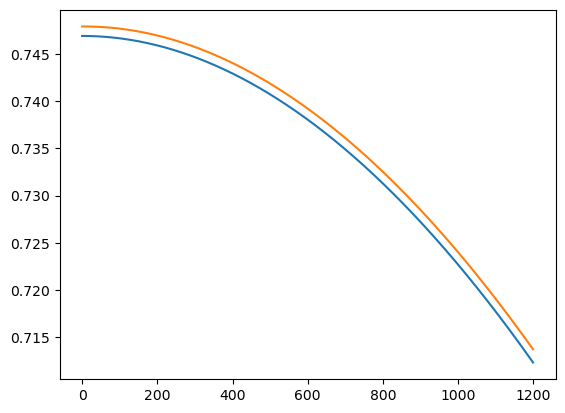

In [453]:
plt.plot(variable_range['obsCdc20'][0:1200]/200)
plt.plot(y_out1['obsCdc20'][0:1200]/200)

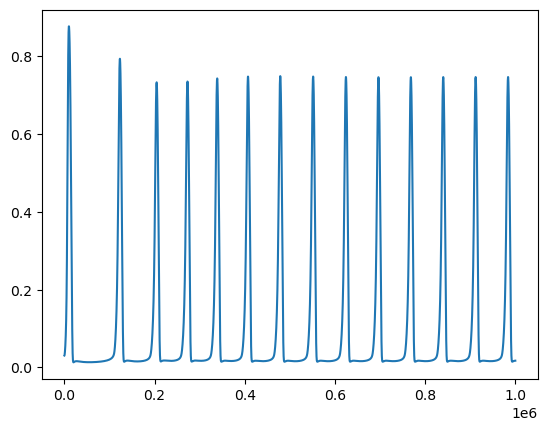

In [454]:
plt.plot(y_out['obsCdc20']/200)


In [528]:
len(y_out1)

1000001

In [529]:
i = 0
j = 0
dif = [variable_range[j][num]/200-y_out1[i][num]/200 for num in range(19)]
norm(dif)

0.004358898943540605

In [473]:
tmp=np.asarray(variable_range[i].tolist())
test=np.asarray(variable_range[j].tolist())-np.asarray(y_out1[i].tolist())
norm(test[0:19]/200)


0.004358898943540611

In [458]:
dists = [0]*len(variable_range)
for j in range(0, len(variable_range)):
    dif = np.asarray(variable_range[j].tolist())-np.asarray(y_out1[i].tolist())
    dists[j] = norm(dif[0:19]/200)

835150

In [536]:
i=166000
window = y_out[peaks_half[-2]+i+tmp_loc-5000:peaks_half[-1]+i+tmp_loc+5000]

In [537]:
dists = [0]*len(window)
for j in range(0, len(window)):
    dif = np.asarray(window[j].tolist())-np.asarray(y_out1[i].tolist())
    dists[j] = norm(dif[0:19]/200)

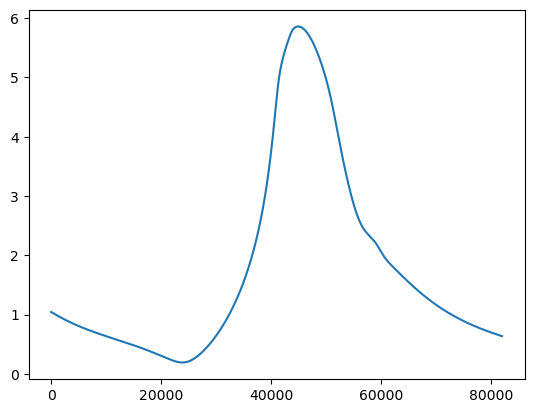

In [538]:
plt.plot(dists)

In [539]:
min(dists)

0.19207297105480642

In [467]:
z=[0]*(round((len(y_out1)/2000))+1)
n=0

In [468]:
for i in range(0, len(y_out1), 2000):
    
    dists = [0]*len(variable_range)
    for j in range(0, len(variable_range)):
        dif = np.asarray(variable_range[j].tolist())-np.asarray(y_out1[i].tolist())
        dists[j] = norm(dif[0:19]/200)
    
    z[n] = min(dists)
    n=n+1
    if n%100 == 0:
        print(n)

100
200
300
400
500


In [ ]:
tmp = [num+0.0001 for num in z]

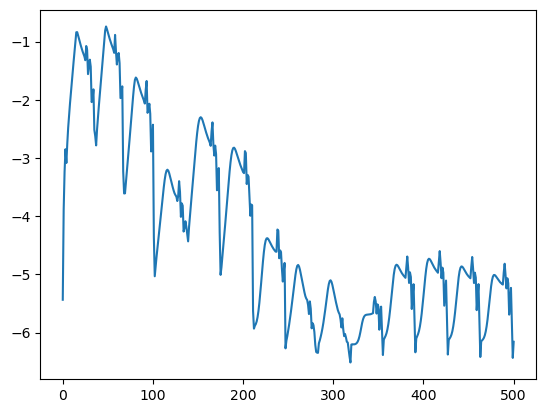

In [469]:
logz = [math.log(num) for num in z]
plt.plot(logz)

In [540]:
z=[0]*(round((len(y_out1)/2000))+1)
n=0
for i in range(0, len(y_out1), 2000):

    window = y_out[peaks_half[-2]+i+tmp_loc-5000:peaks_half[-1]+i+tmp_loc+5000]
    dists = [0]*len(window)
    for j in range(0, len(window)):
        dif = np.asarray(window[j].tolist())-np.asarray(y_out1[i].tolist())
        dists[j] = norm(dif[0:19]/200)
    
    z[n] = min(dists)
    n=n+1
    if n%100 == 0:
        print(n)

100
200
300
400
500


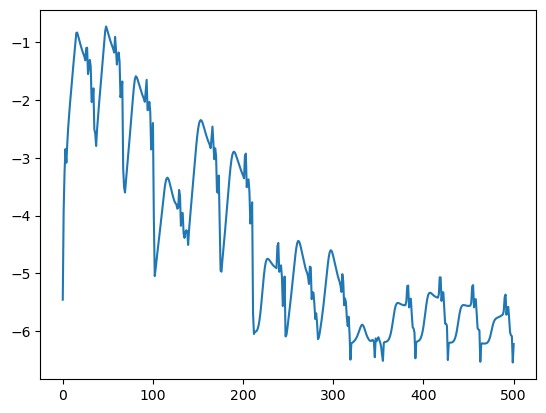

In [541]:
logz = [math.log(num) for num in z]
plt.plot(logz)